# Snow Disappearance and SWE Reconstruction

This example notebook walks through calculating the **Date of Snow Disappearance (DSD)** from predicted snow-covered area (SCA) rasters and using those snow disappearance dates to estimate spring **Snow Water Equivalent (SWE)**.

We assume you have already generated binary snow cover (`*SCA.tif`) images for your study area (see the *Search and Download* and *Quick Start* notebooks for how to download PlanetScope scenes and predict SCA).

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np

import planetsca as ps

/Users/eddy/Documents/Programming/DS Hydro/planetsca/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Calculate Date of Snow Disappearance (DSD)

First, point `data_direc` to the folder containing your `<YYYYMMDD>*SCA.tif` files and list the water years you want to process. You can run this over a single melt season or across multiple years.

The `starting_array` parameter lets you specify the index of the first image near peak snowpack for each year so that early-winter snow events before the main spring melt season are skipped (use `0` to start from the first available image).

In [2]:
# directory containing your predicted *SCA.tif rasters
data_direc = "./example_images/SCA/"

# water years to process (can be one or multiple years, e.g. [2020, 2021, 2022])
years = [2022]

# target water year to save the stacked snow cover cube for SWE reconstruction
year_select = 2022

# index of the first image near peak snow accumulation for each year in `years`
starting_array = [7]

Now run `ps.post_process.process_DSD` to stack the snow cover maps, fill missing pixels, filter out brief single-date snow fluctuations, and compute the snow disappearance date (in days since October 1), domain-median DSD anomaly, and observation uncertainty for each pixel:

In [3]:
dsd_saver, dsd_anomaly_saver, dsd_uncertain_saver = ps.post_process.process_DSD(
    years=years,
    data_direc=data_direc,
    starting_array=starting_array,
    year_select=year_select,
)

Visualize the resulting DSD, DSD anomaly, and DSD uncertainty maps for our target year:

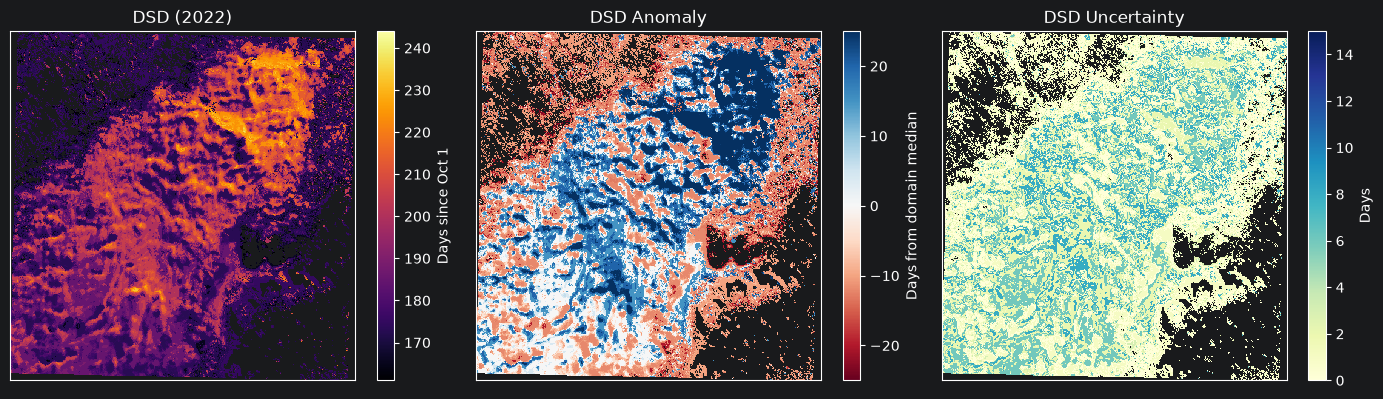

In [4]:
year_idx = years.index(year_select)
dsd = dsd_saver[year_idx]
dsd_anomaly = dsd_anomaly_saver[year_idx]
dsd_uncertainty = dsd_uncertain_saver[year_idx]

fig, [ax1, ax2, ax3] = plt.subplots(
    nrows=1, ncols=3, figsize=(14, 4), tight_layout=True
)

im1 = ax1.imshow(dsd, cmap="inferno", interpolation="none")
ax1.set_title(f"DSD ({year_select})")
plt.colorbar(im1, ax=ax1, label="Days since Oct 1")

im2 = ax2.imshow(dsd_anomaly, cmap="RdBu", vmin=-25, vmax=25, interpolation="none")
ax2.set_title("DSD Anomaly")
plt.colorbar(im2, ax=ax2, label="Days from domain median")

im3 = ax3.imshow(dsd_uncertainty, cmap="YlGnBu", vmin=0, vmax=15, interpolation="none")
ax3.set_title("DSD Uncertainty")
plt.colorbar(im3, ax=ax3, label="Days")

for ax in [ax1, ax2, ax3]:
    ax.set_xticks([])
    ax.set_yticks([])

## 2. Classify Snow Persistence Zones

Across mountain basins, wind drifting, aspect, and shading create repeatable spatial patterns in snow melt-out timing. Using `ps.post_process.process_SnowClass`, we can group the study area into four equal-area quartiles based on the average DSD anomaly (`0` = earliest melt-out to `3` = latest melt-out).

In [5]:
snow_classes = ps.post_process.process_SnowClass(dsd_anomaly_saver)

[-11.   0.  15.]


[]

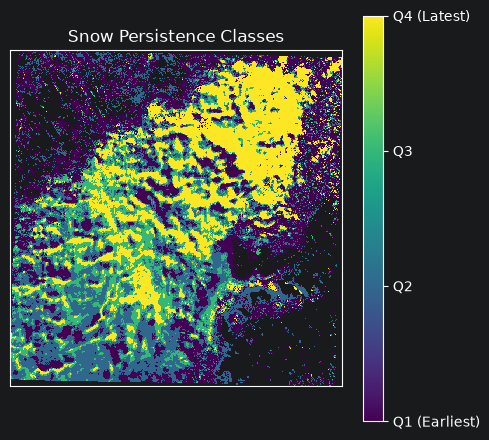

In [6]:
fig, ax = plt.subplots(figsize=(5, 4.5), tight_layout=True)
im = ax.imshow(snow_classes, cmap="viridis", vmin=0, vmax=3, interpolation="none")
cbar = plt.colorbar(im, ax=ax, ticks=[0, 1, 2, 3])
cbar.ax.set_yticklabels(["Q1 (Earliest)", "Q2", "Q3", "Q4 (Latest)"])
ax.set_title("Snow Persistence Classes")
ax.set_xticks([])
ax.set_yticks([])

## 3. Compute Fractional Snow-Covered Area (fSCA) and Set Up Forcing Data

When `year_select` is provided, `process_DSD` saves the quality-controlled snow cover stack (`DSD_stacked.npy`) and observation dates (`DSD_daydiff.npy`) in `processed_<year_select>/`. We can pass these to `ps.reconstruct_swe.process_fSCA` to compute the domain-wide fSCA time series and define the active melt fitting window.

In [7]:
processed_dir = os.path.join(data_direc, f"processed_{year_select}")
dsd_cube = np.load(os.path.join(processed_dir, "DSD_stacked.npy"))
daydiff = np.load(os.path.join(processed_dir, "DSD_daydiff.npy"))

(
    fsca,
    idx_start,
    idx_end,
    daydiff_filt,
    fsca_filt,
    dsd_cube_filt,
    dsd_filt,
) = ps.reconstruct_swe.process_fSCA(dsd_cube.copy(), daydiff, snow_classes, dsd)

To convert snow disappearance dates into SWE, we need two meteorological inputs from a nearby weather station, snow pillow (e.g., SNOTEL or CDEC), or gridded reanalysis product for our study area:

1. `dailySW`: A 1D array of daily mean incoming shortwave radiation ($\text{W/m}^2$) for each day of the water year starting October 1.
2. `MF`: A two-element array `[melt_factor, intercept]` from a linear fit of cumulative snowmelt (m of SWE) against cumulative shortwave radiation ($\text{W/m}^2 \cdot \text{day}$) at a reference snow pillow during the melt season.

In [8]:
# Day of water year (0 = Oct 1, 364 = Sep 30)
wy_days = np.arange(365)

# Example daily incoming shortwave radiation (W/m^2) for the water year.
# Replace this with your local station or reanalysis shortwave series:
# dailySW = pd.read_csv('my_station_sw.csv')['sw_wm2'].to_numpy()
dailySW = 120.0 + 220.0 * np.clip(np.sin(np.pi * (wy_days - 40) / 320), 0, None)

# Linear snow-pillow melt relationship: [melt_factor (m per W/m^2/day), intercept (m)].
# If you have daily pillow SWE and shortwave observations over the melt window, you can fit this directly:
# MF = np.polyfit(np.cumsum(pillow_sw), cumulative_pillow_melt, 1)
MF = np.array([9.16e-5, 0.056])

## 4. Estimate SWE with Three Reconstruction Techniques

### Technique 1: Snow Pillow Melt Rate

The simplest approach assumes the snow pillow's melt rate (`MF`) applies uniformly across the entire study area. For each pixel, `ps.reconstruct_swe.reconstruct_pillow_SWE` sums incoming shortwave radiation from the start of the melt period (`daydiff_filt[0]`) through the pixel's snow disappearance date (`dsd`) and converts that cumulative radiation into initial SWE:

In [9]:
swe_pillow = ps.reconstruct_swe.reconstruct_pillow_SWE(
    dsd=dsd,
    dsd_filt=dsd_filt,
    daydiff_filt=daydiff_filt,
    dailySW=dailySW.copy(),
    MF=MF,
)
print(f"Domain mean initial SWE (snow pillow rate): {np.nanmean(swe_pillow):.2f} m")

Domain mean initial SWE (snow pillow rate): 0.92 m


### Technique 2: Domain-Wide fSCA Calibration

A nearby snow pillow may sit at a different elevation, aspect, or canopy density than the study area as a whole. `ps.reconstruct_swe.fit_domain_melt_factor` adjusts the domain-wide melt factor by simulating the melt-out of a lognormal SWE distribution (`ps.reconstruct_swe.simulate_fSCA`) and finding the melt factor (`B_domain`), SWE coefficient of variation (`C_domain`), and SWE offset that best match the observed satellite fSCA curve:

In [10]:
B_domain, C_domain, offset_domain, mse_domain = (
    ps.reconstruct_swe.fit_domain_melt_factor(
        SWE_map_base=swe_pillow,
        dailySW=dailySW.copy(),
        daydiff_filt=daydiff_filt,
        fsca_filt=fsca_filt,
        MF=MF,
    )
)

# Reconstruct the domain-calibrated SWE map using the fitted melt factor B_domain
swe_domain = ps.reconstruct_swe.reconstruct_pillow_SWE(
    dsd=dsd,
    dsd_filt=dsd_filt,
    daydiff_filt=daydiff_filt,
    dailySW=dailySW.copy(),
    MF=np.array([B_domain, 0.0]),
)

best model parameters
Melt Factor:  8.436842105263159e-05
SWE CoV:  0.5
Initial SWE offset:  0.09154295443986261


### Technique 3: Snow-Class fSCA Calibration

Melt rates can also vary across different terrain zones within the same basin. `ps.reconstruct_swe.fit_class_melt_factors` repeats the fSCA calibration separately for each of the four snow-persistence classes from Step 2, yielding a tailored melt factor for each quartile:

In [11]:
B_class, C_class, offset_class = ps.reconstruct_swe.fit_class_melt_factors(
    SWE_map_base=swe_pillow,
    dailySW=dailySW.copy(),
    daydiff_filt=daydiff_filt,
    dsdCube=dsd_cube.copy(),
    daydiff=daydiff,
    snow_classes=snow_classes,
    idx_start=idx_start,
    idx_end=idx_end,
    MF=MF,
)

for q, (b_val, c_val) in enumerate(zip(B_class, C_class)):
    print(
        f"Class Q{q + 1}: Melt Factor = {b_val:.6f} m/(W/m^2/day), SWE CV = {c_val:.2f}"
    )

Class Q1: Melt Factor = 0.000108 m/(W/m^2/day), SWE CV = 0.33
Class Q2: Melt Factor = 0.000099 m/(W/m^2/day), SWE CV = 0.33
Class Q3: Melt Factor = 0.000089 m/(W/m^2/day), SWE CV = 0.19
Class Q4: Melt Factor = 0.000099 m/(W/m^2/day), SWE CV = 0.14


We can now apply each class's calibrated melt factor to the pixels belonging to that snow class:

In [12]:
swe_classes = np.full_like(swe_pillow, np.nan)
for class_id, b_val in enumerate(B_class):
    class_swe = ps.reconstruct_swe.reconstruct_pillow_SWE(
        dsd=dsd,
        dsd_filt=dsd_filt,
        daydiff_filt=daydiff_filt,
        dailySW=dailySW.copy(),
        MF=np.array([b_val, 0.0]),
    )
    swe_classes[snow_classes == class_id] = class_swe[snow_classes == class_id]

## 5. Visualize and Compare Results

Compare the spatial SWE maps from all three techniques side by side:

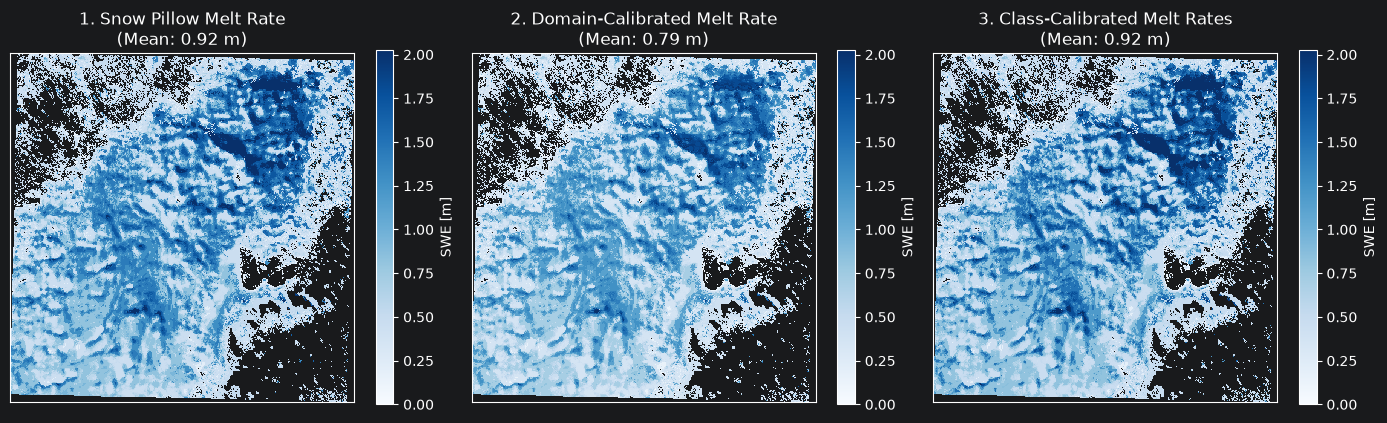

In [13]:
vmax = np.nanpercentile(swe_pillow, 98)
fig, [ax1, ax2, ax3] = plt.subplots(
    nrows=1, ncols=3, figsize=(14, 4.2), tight_layout=True
)

for ax, swe_map, title in zip(
    [ax1, ax2, ax3],
    [swe_pillow, swe_domain, swe_classes],
    [
        "1. Snow Pillow Melt Rate",
        "2. Domain-Calibrated Melt Rate",
        "3. Class-Calibrated Melt Rates",
    ],
):
    im = ax.imshow(swe_map, cmap="Blues", vmin=0, vmax=vmax, interpolation="none")
    ax.set_title(f"{title}\n(Mean: {np.nanmean(swe_map):.2f} m)")
    ax.set_xticks([])
    ax.set_yticks([])
    plt.colorbar(im, ax=ax, label="SWE [m]")

Finally, let's plot the simulated fSCA depletion curves against the observed PlanetScope fSCA time series:

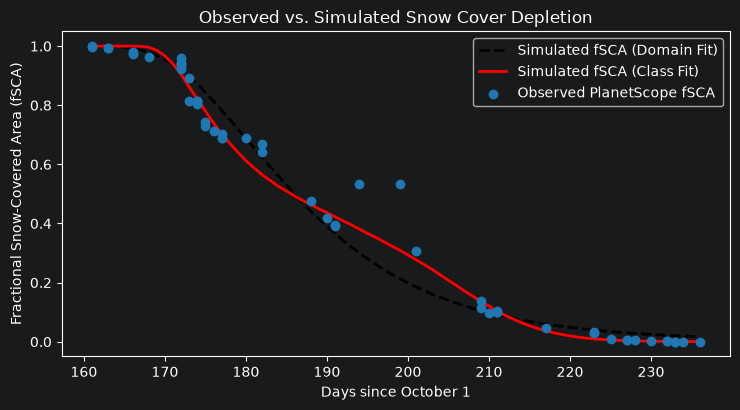

In [14]:
D = np.linspace(0.0001, 7, 2000)

# Domain-wide simulated fSCA
sim_fsca_domain = ps.reconstruct_swe.simulate_fSCA(
    D=D,
    meanSWE=np.nanmean(swe_pillow),
    CV=C_domain,
    SW=dailySW.copy(),
    MD=daydiff_filt[0],
    MF=B_domain,
    offset=offset_domain,
)

# Area-weighted class-calibrated simulated fSCA
total_valid_px = np.sum(~np.isnan(snow_classes))
sim_fsca_classes = np.zeros_like(sim_fsca_domain)
for class_id, (b_val, c_val, off_val) in enumerate(zip(B_class, C_class, offset_class)):
    class_mask = snow_classes == class_id
    class_weight = np.sum(class_mask) / total_valid_px
    class_fsca = ps.reconstruct_swe.simulate_fSCA(
        D=D,
        meanSWE=np.nanmean(swe_pillow[class_mask]),
        CV=c_val,
        SW=dailySW.copy(),
        MD=daydiff_filt[0],
        MF=b_val,
        offset=off_val,
    )
    sim_fsca_classes += class_weight * class_fsca

fig, ax = plt.subplots(figsize=(7.5, 4.2), tight_layout=True)
days = np.arange(daydiff_filt[0], daydiff_filt[-1] + 1)
ax.plot(
    days, sim_fsca_domain[days], "--k", linewidth=2, label="Simulated fSCA (Domain Fit)"
)
ax.plot(
    days, sim_fsca_classes[days], "-r", linewidth=2, label="Simulated fSCA (Class Fit)"
)
ax.scatter(
    daydiff_filt,
    fsca_filt,
    color="tab:blue",
    zorder=5,
    label="Observed PlanetScope fSCA",
)
ax.set_xlabel("Days since October 1")
ax.set_ylabel("Fractional Snow-Covered Area (fSCA)")
ax.set_title("Observed vs. Simulated Snow Cover Depletion")
ax.legend()